# 33. 머신러닝(지도) + SHAP — LightGBM / CatBoost / RF

2022 우수작의 **'AutoML 앙상블 + CatBoost 비교 + SHAP'**을 우리 데이터에 맞게 바꾼 것.

- 무작위 교차검증 대신 **Run 하나씩 빼고 검증(LORO)** — 같은 Run 이웃 샷 누수 차단
- 하이퍼파라미터 사전 고정 (불량 15~32개로 튜닝하면 과적합)
- 실험 조건: 변수 `free17` / `raw21` / `free17+raw21` × 불균형 `weight` / `smote` × 모델 3종
- 지표: AP(PR-AUC), 상위 k%, Run별 상위 10%, 최종 모델 대비 ΔAP

**준비**: `20b_final_test` 먼저 실행. `pip install lightgbm catboost shap imbalanced-learn`

In [1]:
import pandas as pd
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 250)
from plot_style import set_style; set_style()
import gbm_shap as G
G.available()

{'lightgbm': True, 'catboost': True, 'imblearn': True, 'shap': True}

## 1. LORO 실험
처음에 Run별 샷·불량 수가 출력됨 → 불량이 한 Run에 몰려 있으면 그 Run을 뺄 때 학습할 불량이 거의 없음(학습 불가 Run으로 표시).

In [2]:
R = G.run(products=('cn7', 'rg3'))

라이브러리: {'lightgbm': True, 'catboost': True, 'imblearn': True, 'shap': True} | 사용 모델: ['lgbm', 'catboost', 'rf'] | 불균형: ['weight', 'smote']
[cn7] labeled 1,979샷 (평가 1,974, 불량 15)
          샷  불량  가스  미성형
run_id                  
cn7_R1  188  14  11    3
cn7_R2  418   0   0    0
cn7_R3  309   0   0    0
cn7_R4  189   0   0    0
cn7_R5  407   0   0    0
cn7_R6  463   1   0    1
  [cn7] lgbm|free17|weight: ② AP 0.004 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] lgbm|free17|smote: ② AP 0.004 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] catboost|free17|weight: ② AP 0.004 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] catboost|free17|smote: ② AP 0.004 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] rf|free17|weight: ② AP 0.005 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] rf|free17|smote: ② AP 0.004 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] lgbm|raw21|weight: ② AP 0.004 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] lgbm|raw21|smote: ② AP 0.004 | ① AP 0.014 | 학습 불가 Run ['cn7_R1']
  [cn7] catboost|raw21|w

## 2. 한눈 표 — 최종 모델(비지도) 대비

In [3]:
cols = ['제품', '모델', '① AP', '① 상위10%', '② AP', '② AP 95%CI', '② AP_가스', '② AP_미성형',
        'Run별 상위10%', 'Run별 상위10% 가스', 'Run별 상위10% 미성형',
        'ΔAP(②, vs 최종)', 'ΔAP 95%CI', 'P(최종보다 좋음)', '유의하게 좋음', '학습 불가 Run']
for p in ('cn7', 'rg3'):
    print(f'===== {p.upper()} (② AP 순) =====')
    display(R['summary'].query('제품 == @p')[cols].sort_values('② AP', ascending=False).round(3))

===== CN7 (② AP 순) =====


,제품,모델,① AP,① 상위10%,② AP,② AP 95%CI,② AP_가스,② AP_미성형,Run별 상위10%,Run별 상위10% 가스,Run별 상위10% 미성형,"ΔAP(②, vs 최종)",ΔAP 95%CI,P(최종보다 좋음),유의하게 좋음,학습 불가 Run
0,cn7,"M_maha_free (최종, 비지도)",0.373,8/17,0.212,"[0.011, 0.416]",0.007,0.751,4/15,1/11,3/4,NaN,NaN,NaN,NaN,
11,cn7,rf|raw21|weight,0.014,0/17,0.005,"[0.005, 0.006]",0.004,0.002,0/15,0/11,0/4,-0.204,"[-0.409, -0.003]",0.010,-,cn7_R1
17,cn7,rf|free17+raw21|weight,0.014,0/17,0.005,"[0.005, 0.006]",0.004,0.002,0/15,0/11,0/4,-0.204,"[-0.409, -0.003]",0.010,-,cn7_R1
12,cn7,rf|raw21|smote,0.014,0/17,0.005,"[0.005, 0.006]",0.004,0.001,0/15,0/11,0/4,-0.204,"[-0.409, -0.003]",0.010,-,cn7_R1
5,cn7,rf|free17|weight,0.014,0/17,0.005,"[0.005, 0.006]",0.004,0.002,0/15,0/11,0/4,-0.204,"[-0.410, -0.004]",0.008,-,cn7_R1
18,cn7,rf|free17+raw21|smote,0.014,0/17,0.004,"[0.004, 0.005]",0.003,0.001,0/15,0/11,0/4,-0.204,"[-0.410, -0.004]",0.005,-,cn7_R1
6,cn7,rf|free17|smote,0.014,0/17,0.004,"[0.004, 0.005]",0.003,0.001,0/15,0/11,0/4,-0.204,"[-0.410, -0.004]",0.008,-,cn7_R1
4,cn7,catboost|free17|smote,0.014,0/17,0.004,"[0.004, 0.005]",0.003,0.002,0/15,0/11,0/4,-0.204,"[-0.410, -0.004]",0.008,-,cn7_R1
9,cn7,catboost|raw21|weight,0.014,0/17,0.004,"[0.004, 0.005]",0.003,0.001,1/15,0/11,1/4,-0.204,"[-0.410, -0.004]",0.008,-,cn7_R1
16,cn7,catboost|free17+raw21|smote,0.014,0/17,0.004,"[0.004, 0.005]",0.003,0.001,1/15,0/11,1/4,-0.204,"[-0.410, -0.004]",0.008,-,cn7_R1


===== RG3 (② AP 순) =====


,제품,모델,① AP,① 상위10%,② AP,② AP 95%CI,② AP_가스,② AP_미성형,Run별 상위10%,Run별 상위10% 가스,Run별 상위10% 미성형,"ΔAP(②, vs 최종)",ΔAP 95%CI,P(최종보다 좋음),유의하게 좋음,학습 불가 Run
23,rg3,catboost|free17|smote,0.040,6/25,0.087,"[0.052, 0.184]",0.049,0.082,8/32,5/22,3/10,0.023,"[-0.030, +0.119]",0.793,-,
20,rg3,lgbm|free17|weight,0.038,6/25,0.085,"[0.057, 0.174]",0.053,0.051,8/32,4/22,4/10,0.021,"[-0.025, +0.106]",0.822,-,
24,rg3,rf|free17|weight,0.039,7/25,0.081,"[0.053, 0.178]",0.057,0.043,5/32,2/22,3/10,0.018,"[-0.028, +0.110]",0.776,-,
26,rg3,lgbm|raw21|weight,0.037,1/25,0.075,"[0.039, 0.148]",0.078,0.015,2/32,2/22,0/10,0.012,"[-0.048, +0.086]",0.574,-,
33,rg3,lgbm|free17+raw21|smote,0.032,3/25,0.072,"[0.045, 0.161]",0.070,0.017,8/32,6/22,2/10,0.009,"[-0.039, +0.106]",0.646,-,
21,rg3,lgbm|free17|smote,0.029,4/25,0.072,"[0.049, 0.149]",0.045,0.044,6/32,3/22,3/10,0.008,"[-0.032, +0.086]",0.638,-,
22,rg3,catboost|free17|weight,0.034,6/25,0.069,"[0.049, 0.128]",0.046,0.035,7/32,3/22,4/10,0.006,"[-0.043, +0.073]",0.614,-,
32,rg3,lgbm|free17+raw21|weight,0.023,3/25,0.065,"[0.048, 0.117]",0.053,0.021,8/32,6/22,2/10,0.001,"[-0.034, +0.050]",0.541,-,
19,rg3,"M_maha_free (최종, 비지도)",0.024,2/25,0.064,"[0.051, 0.101]",0.050,0.021,3/32,2/22,1/10,NaN,NaN,NaN,NaN,
25,rg3,rf|free17|smote,0.029,6/25,0.061,"[0.044, 0.121]",0.040,0.035,6/32,5/22,1/10,-0.003,"[-0.050, +0.055]",0.444,-,


In [4]:
# 조건별 평균 (2022 '파생변수 유무 / 불균형 처리' 비교표의 대응)
s = R['summary'].query('알고리즘 != "maha"')
for by in ('변수', '불균형', '알고리즘'):
    display(s.groupby(['제품', by])[['① AP', '② AP', '② AP_가스', '② AP_미성형']].mean().round(3))

① AP   ② AP  ② AP_가스  ② AP_미성형
제품  변수                                           
cn7 free17        0.014  0.004    0.003     0.001
    free17+raw21  0.014  0.004    0.003     0.001
    raw21         0.014  0.004    0.003     0.001
rg3 free17        0.035  0.076    0.048     0.048
    free17+raw21  0.025  0.059    0.049     0.018
    raw21         0.023  0.052    0.043     0.016

① AP   ② AP  ② AP_가스  ② AP_미성형
제품  불균형                                    
cn7 smote   0.014  0.004    0.003     0.001
    weight  0.014  0.004    0.003     0.001
rg3 smote   0.027  0.061    0.045     0.029
    weight  0.029  0.064    0.049     0.026

① AP   ② AP  ② AP_가스  ② AP_미성형
제품  알고리즘                                     
cn7 catboost  0.014  0.004    0.003     0.001
    lgbm      0.014  0.004    0.003     0.001
    rf        0.014  0.005    0.004     0.001
rg3 catboost  0.028  0.062    0.043     0.032
    lgbm      0.031  0.070    0.057     0.027
    rf        0.025  0.055    0.041     0.023

## 3. SHAP — 모델이 무엇을 보고 불량이라 하나
기본 설정 `lgbm | free17+raw21 | weight` (파생변수와 원값 중 무엇이 쓰이는지 같이 보려고).
2번 표에서 더 나은 설정이 있으면 인자만 바꾸면 됨.
⚠ 전체 labeled로 다시 학습한 설명 → 성능 근거가 아니라 '모델이 보는 것'의 기술

In [5]:
import os; os.makedirs('./outputs/gbm_shap', exist_ok=True)
SH = {}
for p in ('cn7', 'rg3'):
    SH[p] = G.shap_explain(p, model='lgbm', feature_set='free17+raw21', imbalance='weight')
    print(f'===== {p.upper()} SHAP 중요도 상위 15 =====')
    display(SH[p]['importance'].head(15).round(4))

===== CN7 SHAP 중요도 상위 15 =====


c:\anaconda\envs\kamp\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,변수,평균 |SHAP| (전체),평균 SHAP (가스 샷),평균 SHAP (미성형 샷),평균 SHAP (정상 샷),구분
0,Mold_Temperature_4_raw,0.3966,2.6144,2.5902,-0.1059,원값(raw)
1,Clamp_Close_Time_raw,0.2478,2.5572,1.8939,0.0015,원값(raw)
2,Plasticizing_Position_raw,0.2037,2.3223,1.8527,-0.0406,원값(raw)
3,dev_Mold_Temperature_3,0.1356,1.1478,1.5401,-0.0150,파생(free)
4,hopper_slope20,0.1233,1.5844,1.7010,-0.0186,파생(free)
5,mold_rise,0.0802,0.6026,0.6154,0.0111,파생(free)
6,Mold_Temperature_3_raw,0.0712,1.1114,1.0446,0.0250,원값(raw)
7,Barrel_Temperature_6_raw,0.0636,0.3939,0.0327,-0.0012,원값(raw)
8,dev_Hopper_Temperature,0.0632,0.4759,0.2974,-0.0017,파생(free)
9,Barrel_Temperature_5_raw,0.0621,0.2103,0.0876,-0.0015,원값(raw)


===== RG3 SHAP 중요도 상위 15 =====


c:\anaconda\envs\kamp\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,변수,평균 |SHAP| (전체),평균 SHAP (가스 샷),평균 SHAP (미성형 샷),평균 SHAP (정상 샷),구분
0,mold_slope20,0.4736,1.2062,1.0898,-0.0830,파생(free)
1,Barrel_Temperature_3_raw,0.4156,0.6721,0.5065,-0.0297,원값(raw)
2,dev_Mold_Temperature_3,0.3721,0.7848,0.8465,-0.0382,파생(free)
3,hopper_rise,0.3257,0.5738,0.6845,-0.0384,파생(free)
4,hopper_slope20,0.3235,0.6604,0.7545,-0.0474,파생(free)
5,dev_Plasticizing_Time,0.2969,0.6941,0.7845,-0.0395,파생(free)
6,Barrel_Temperature_5_raw,0.2769,0.3529,0.4529,-0.0227,원값(raw)
7,ev_max_abs_dev,0.2671,0.7017,0.6311,-0.0370,파생(free)
8,dev_Max_Switch_Over_Pressure,0.2302,0.3554,0.5077,-0.0025,파생(free)
9,Plasticizing_Time_raw,0.2210,0.5168,0.6743,-0.0406,원값(raw)


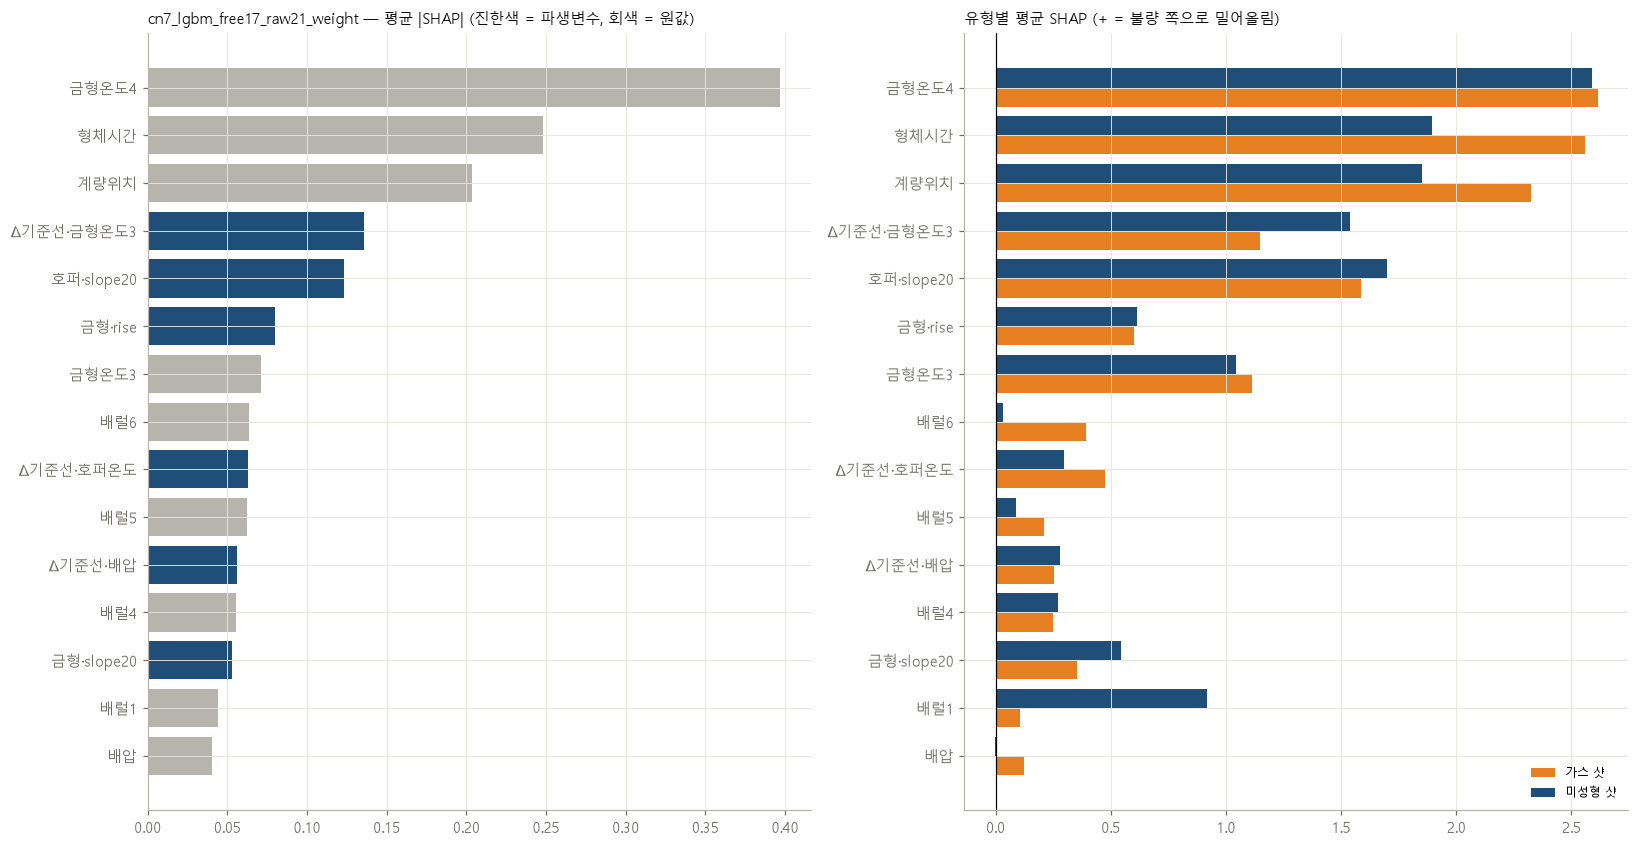

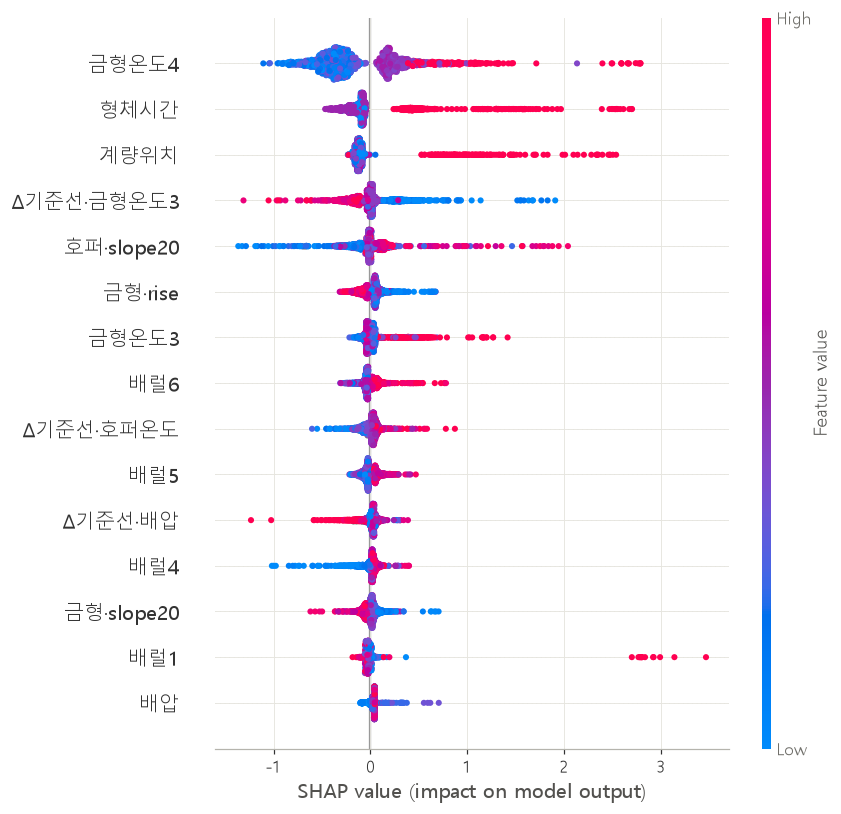

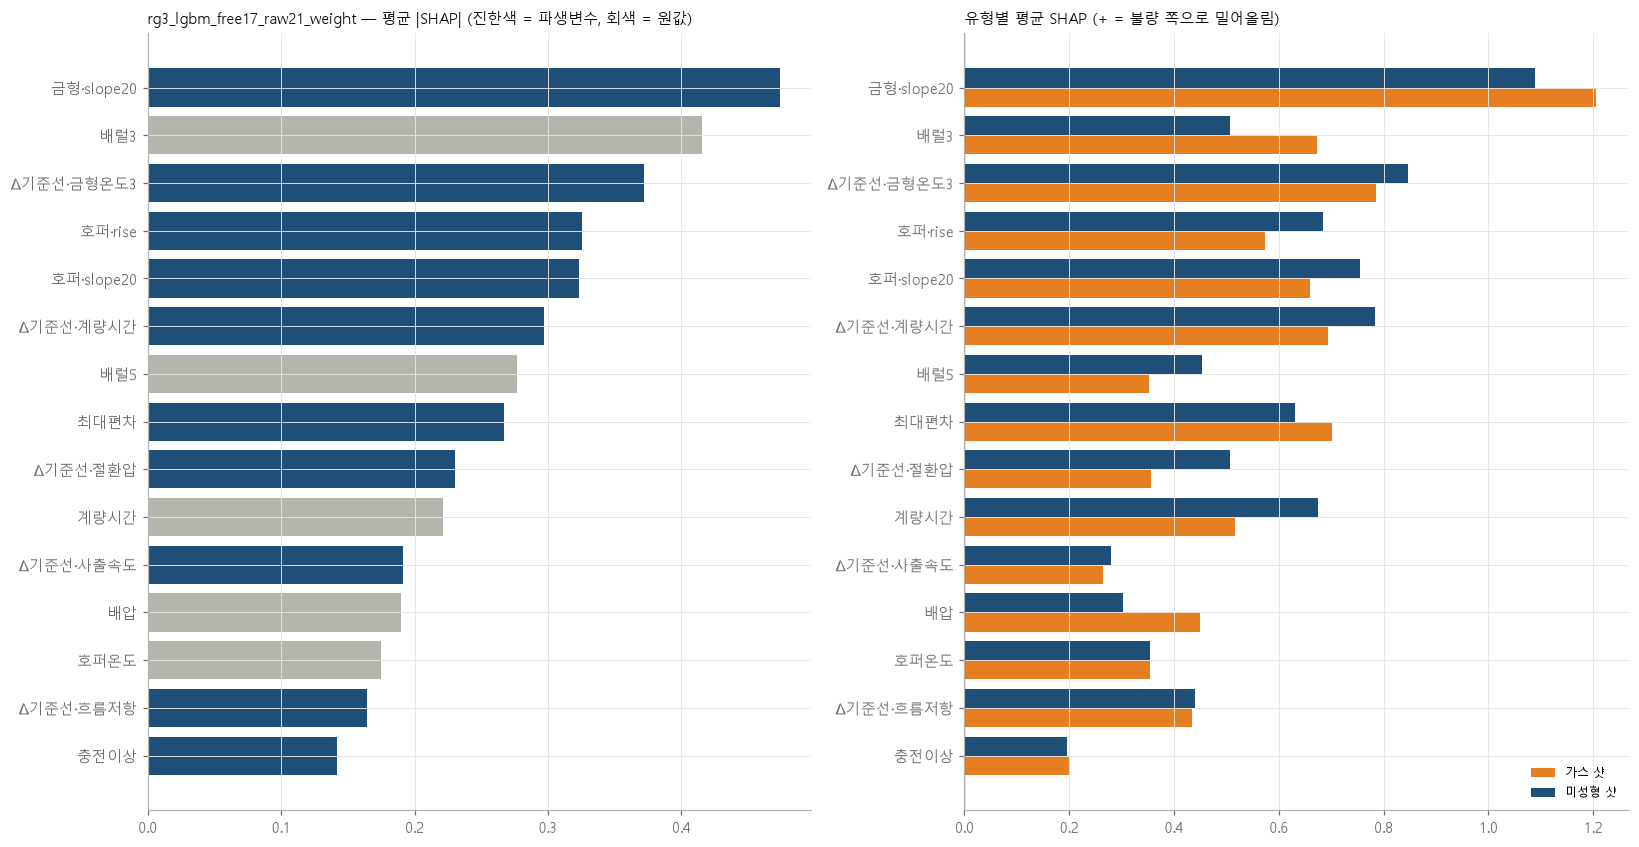

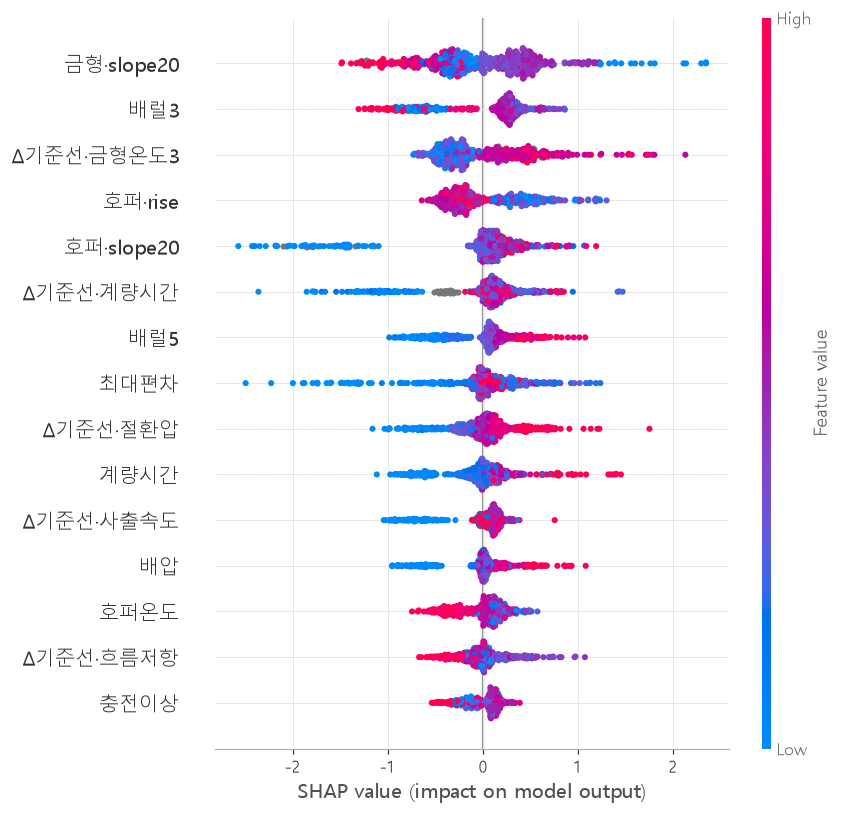

In [6]:
for p in ('cn7', 'rg3'):
    G.plot_shap(SH[p], save_dir='./outputs/gbm_shap')

## 4. 샷 하나의 워터폴 (2022 '데이터 객체 시각화'의 대응)

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\gbm_shap.py:280: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.savefig(f'{save_dir}/{S["tag"]}_waterfall_{which}_{k}.png', dpi=150, bbox_inches='tight')
c:\anaconda\envs\kamp\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


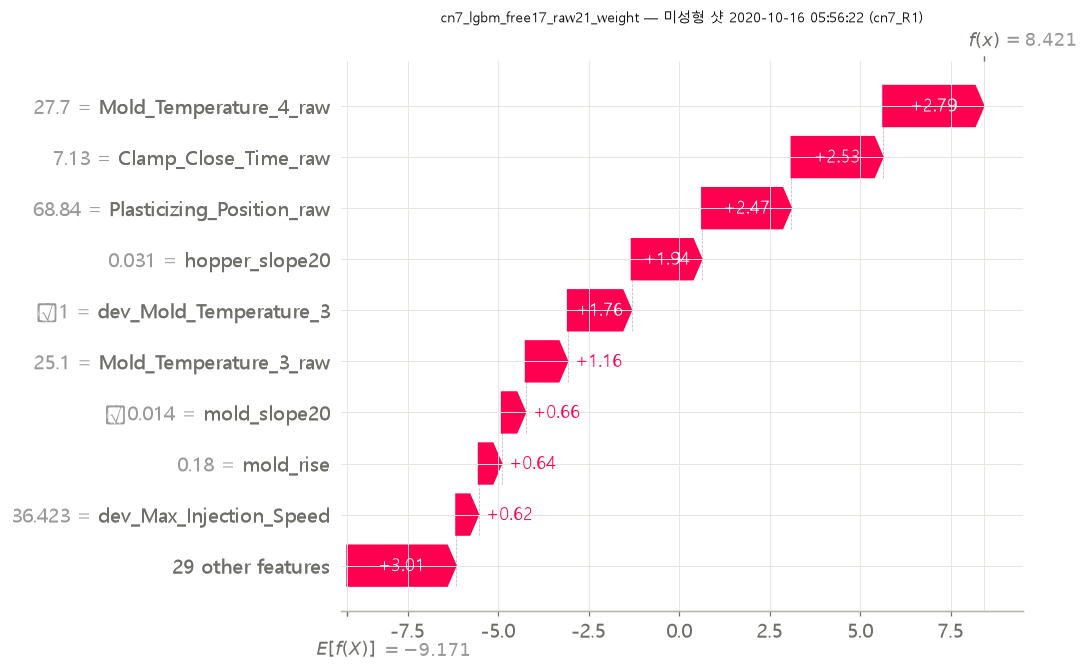

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\gbm_shap.py:280: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.savefig(f'{save_dir}/{S["tag"]}_waterfall_{which}_{k}.png', dpi=150, bbox_inches='tight')
c:\anaconda\envs\kamp\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


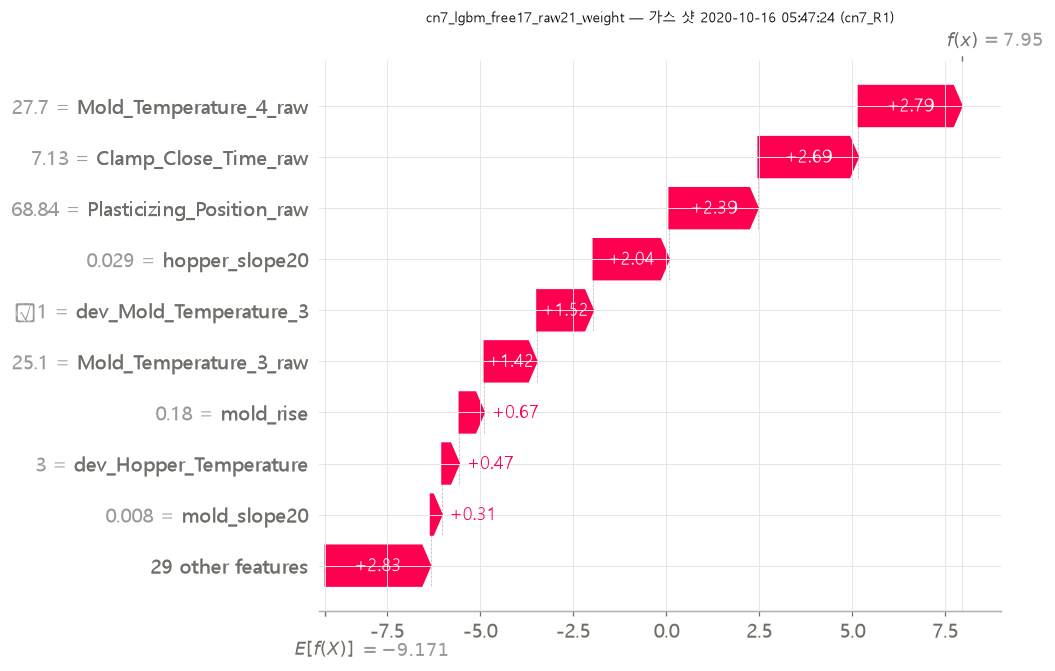

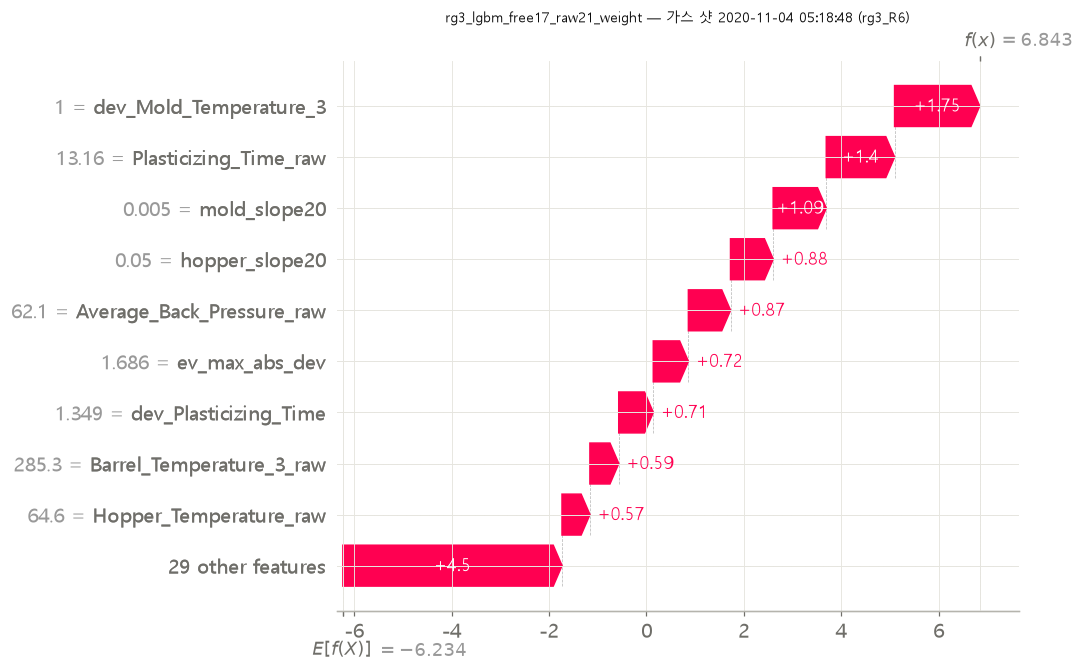

In [7]:
G.plot_waterfall(SH['cn7'], '미성형', save_dir='./outputs/gbm_shap')
G.plot_waterfall(SH['cn7'], '가스', save_dir='./outputs/gbm_shap')
G.plot_waterfall(SH['rg3'], '가스', save_dir='./outputs/gbm_shap')